# Notebook 05 — H3 Supply-Axis Evaluation

**Scientific scope:** Authoritative supply-axis evaluation of the selected H3
checkpoint (`h3_kub_localizer_sigma_adaptive_sizeaware_seed42_clean_v3`, epoch 54)
on canonical clean-v3 FULL_FIELD VAL (103 images, 152 GT components) under the
frozen proposal decode (threshold=0.10, margin=0.20, top_k=5, nms_iou=0.30).

**This notebook does NOT:**
- Train or retrain any model
- Evaluate alternate checkpoints or proposal policies
- Run the Phase-14 regional refiner
- Perform downstream Dice adjudication
- Access TEST or external TEST
- Start Phase 15
- Perform formal H3 adjudication

**Evaluation state:** `H3_SUPPLY_AXIS_EVALUATION_COMPLETE__FORMAL_ADJUDICATION_PENDING`

## 2. Current Governance State

| Item | Status |
|------|--------|
| H3 Training | COMPLETE (69 epochs, early stopping patience 15) |
| Checkpoint Selection Replay | PASS (epoch 54, val_localization_recall=0.6382) |
| Supply-Axis Evaluation | COMPLETE (this notebook) |
| Formal H3 Adjudication | PENDING (Notebook 06, not authorized) |
| Phase-14 Refiner Evaluation | NOT PERFORMED in this task |
| Phase 15 | NOT_STARTED_AND_NOT_AUTHORIZED |
| TEST | CLOSED (0 reads) |
| External TEST | CLOSED (0 reads) |

## 3. H3 Training Checkpoint Binding

In [1]:
import json, hashlib, sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path('D:/Softfors/jup')
sys.path.insert(0, str(ROOT))

# Load authoritative artifacts
closure = json.loads((ROOT / 'reports/audits/h3_proposal_supply_training_closure.json').read_text())
replay = json.loads((ROOT / 'reports/audits/h3_checkpoint_selection_replay.json').read_text())
eval_artifact = json.loads((ROOT / 'reports/audits/h3_supply_axis_evaluation.json').read_text())
criteria = json.loads((ROOT / 'reports/audits/h3_proposal_supply_success_failure_criteria.json').read_text())

EXPERIMENT_ID = closure['experiment_id']
SELECTED_EPOCH = closure['best_epoch']
CHECKPOINT_PATH = ROOT / closure['checkpoint_integrity']['best_pt']['path']
EXPECTED_SHA = closure['implementation_shas']['best_pt']

# Verify checkpoint SHA from disk
ckpt_sha = hashlib.sha256(CHECKPOINT_PATH.read_bytes()).hexdigest()
assert ckpt_sha == EXPECTED_SHA, f"Checkpoint SHA mismatch: {ckpt_sha} != {EXPECTED_SHA}"

print(f"Experiment ID: {EXPERIMENT_ID}")
print(f"Selected epoch: {SELECTED_EPOCH}")
print(f"Checkpoint path: {CHECKPOINT_PATH}")
print(f"Checkpoint SHA: {ckpt_sha}")
print(f"SHA matches closure: {ckpt_sha == EXPECTED_SHA}")

Experiment ID: h3_kub_localizer_sigma_adaptive_sizeaware_seed42_clean_v3
Selected epoch: 54
Checkpoint path: D:\Softfors\jup\checkpoints\h3_kub_localizer_sigma_adaptive_sizeaware_seed42_clean_v3\best.pt
Checkpoint SHA: d875cac7d09bbc3d32232191f0af2c138e5a74682fc63e4d6e01f30345eca75e
SHA matches closure: True


## 4. Checkpoint-Selection Replay Confirmation

In [2]:
replay_verdict = replay['verdict']
replay_epoch = replay['replay_selected_epoch']
replay_score = replay['replay_selected_score']

print(f"Replay verdict: {replay_verdict}")
print(f"Replay selected epoch: {replay_epoch}")
print(f"Replay selected score: {replay_score}")
print(f"Replay selected val_localization_recall: {replay['replay_selected_val_localization_recall']}")
print(f"Replay selected val_loss: {replay['replay_selected_val_loss']}")
print(f"Early stopping fired: {replay['early_stopping_fired']}")
print(f"Max epochs reached: {replay['max_epochs_reached']}")
print(f"Selected epoch all sources match: {replay['comparisons']['selected_epoch_all_sources_match']}")

Replay verdict: H3_CHECKPOINT_SELECTION_REPLAY_PASS
Replay selected epoch: 54
Replay selected score: [0.6381578947368421, -1.8561325531739452]
Replay selected val_localization_recall: 0.6381578947368421
Replay selected val_loss: 1.8561325531739452
Early stopping fired: True
Max epochs reached: False
Selected epoch all sources match: True


## 5. Trainer Multi-SHA Provenance Caveat

The H3 training trajectory spans multiple trainer revisions:

| Segment | Epochs | Trainer SHA |
|---------|--------|-------------|
| Design-era | — | `37b64310...` |
| Segment 1 | 1–2 | `9099d6de...` |
| Segment 2 | 3–69 | `45bef74f...` |

The exact source bytes for the epoch-1/2 trainer are **unavailable locally**.
We do NOT claim a single trainer SHA produced the complete trajectory.
The selected epoch-54 checkpoint was produced under the final segment trainer (`45bef74f`).
This is carried as provenance only — no training is rerun.

In [3]:
lineage = closure['implementation_shas']['trainer_lineage']
print("Trainer lineage:")
for k, v in lineage.items():
    print(f"  {k}: {v}")
print(f"\nLaunch-era trainer bytes recoverable locally: {closure['implementation_shas']['launch_era_trainer_bytes_recoverable_locally']}")
print(f"Epoch-54 producing trainer: {closure['implementation_shas']['trainer_per_epoch_producer']['54']}")

Trainer lineage:
  design_binding_v2: 37b64310d38222310ce060803e37d17e4b6916ce7c522d925234167dc26da366
  launch_binding_segment_1_epochs_1_2: 9099d6de339aba43d5e92284ea741568f16c7f5c39e7c189c595301ca5cb88f9
  segment_2_epochs_3_plus_expected: 45bef74f4eddb2e376fd768b1da2e0cba743897e30a725241ac6882d60ad3578

Launch-era trainer bytes recoverable locally: False
Epoch-54 producing trainer: 45bef74f4eddb2e376fd768b1da2e0cba743897e30a725241ac6882d60ad3578


## 6. Evaluation Population

Canonical clean-v3 FULL_FIELD VAL:
- **103 images**
- **152 authoritative GT components**
- Size strata: TINY=72, SMALL=28, MEDIUM=36, LARGE=16

Historical v2 population (106/156) is NOT used.

In [4]:
val_pop = eval_artifact['val_population']
print(f"VAL images: {val_pop['images']}")
print(f"VAL components: {val_pop['components']}")
print(f"  TINY: {val_pop['tiny']}")
print(f"  SMALL: {val_pop['small']}")
print(f"  MEDIUM: {val_pop['medium']}")
print(f"  LARGE: {val_pop['large']}")
print(f"  Total: {val_pop['tiny']+val_pop['small']+val_pop['medium']+val_pop['large']}")

VAL images: 103
VAL components: 152
  TINY: 72
  SMALL: 28
  MEDIUM: 36
  LARGE: 16
  Total: 152


## 7. Frozen Decode Configuration

Exactly ONE decode policy — no grid, no search, no alternate threshold.

In [5]:
frozen_decode = eval_artifact['frozen_decode']
print(f"Threshold: {frozen_decode['threshold']}")
print(f"Margin: {frozen_decode['margin']}")
print(f"Top-k: {frozen_decode['top_k']}")
print(f"NMS IoU: {frozen_decode['nms_iou']}")
print(f"Proposal configurations evaluated: {eval_artifact['proposal_configurations_evaluated']}")

Threshold: 0.1
Margin: 0.2
Top-k: 5
NMS IoU: 0.3
Proposal configurations evaluated: 1


## 8. Frozen Success/Failure Criteria

Retrieved from `reports/audits/h3_proposal_supply_success_failure_criteria.json`.

**Primary supply criteria (necessary, not sufficient):**
- Criterion A: zero-proposal TINY ≤ 20/72
- Criterion B: zero-proposal GT ≤ 35/152

**Minimum meaningful improvement:**
- R_H3 = (TinyRecall_H3 - Tg) / G ≥ 0.30
- Tg = 0.7916666666666666, G = 0.20833333333333337

**Failure boundary (fires if ANY):**
- zero-proposal TINY ≥ 45/72
- R_H3 < 0.15

**Interpretation bands:**
- Meaningful: R_H3 ≥ 0.30
- Intermediate: 0.15 ≤ R_H3 < 0.30
- Insufficient: R_H3 < 0.15

**Contamination policy:** Observational only — not used for checkpoint selection or supply verdict.

In [6]:
frozen_refs = criteria['frozen_references']
print("Frozen references:")
for k, v in frozen_refs.items():
    print(f"  {k}: {v}")
print()
print(f"Primary criteria:")
print(f"  A: zero_proposal_TINY <= {criteria['primary_supply_criteria']['zero_proposal_tiny_target_max']}")
print(f"  B: zero_proposal_GT <= {criteria['primary_supply_criteria']['zero_proposal_gt_target_max']}")
print(f"\nR_H3 formula: {criteria['minimum_meaningful_improvement']['formula']}")
print(f"R_H3 gate: {criteria['minimum_meaningful_improvement']['gate']}")
print(f"\nFailure boundary:")
for cond in criteria['failure_boundary']['fires_if_any']:
    print(f"  {cond}")

Frozen references:


  Tg: 0.7916666666666666
  G: 0.20833333333333337
  Dg: 0.6359172411726776
  Dice_gate: 0.6159172411726777
  zero_proposal_tiny_baseline: 57
  zero_proposal_gt_baseline: 79
  val_tiny_total: 72
  val_components_total: 152

Primary criteria:
  A: zero_proposal_TINY <= 20/72
  B: zero_proposal_GT <= 35/152

R_H3 formula: R_H3 = (TinyRecall_H3 - Tg) / G
R_H3 gate: R_H3 >= 0.30

Failure boundary:
  zero_proposal_tiny after H3 >= 45/72 (recovers < 12 of 57)
  R_H3 < 0.15  (TinyRecall_H3 < 0.8229166666666666)


## 9. Baseline Phase-13B Supply State

Frozen baseline from the root-cause/H3 design artifacts:

In [7]:
baseline = eval_artifact['baseline_values']
print("PRE-H3 Phase-13B baseline (frozen decode):")
print(f"  Zero-proposal GT: {baseline['zero_proposal_gt']} / {baseline['val_components']}")
print(f"  Zero-proposal TINY: {baseline['zero_proposal_tiny']} / {baseline['val_tiny']}")
print(f"  TINY recall (any-overlap): {baseline['tiny_recall_baseline']:.10f} ({baseline['val_tiny']-baseline['zero_proposal_tiny']}/{baseline['val_tiny']})")
print(f"  Overall any-overlap recall: {baseline['overall_any_overlap_recall_baseline']:.10f} ({baseline['val_components']-baseline['zero_proposal_gt']}/{baseline['val_components']})")
print(f"  Tg: {baseline['Tg']}")
print(f"  G: {baseline['G']}")
print(f"\n  Source: {baseline['source']}")

PRE-H3 Phase-13B baseline (frozen decode):


  Zero-proposal GT: 79 / 152
  Zero-proposal TINY: 57 / 72
  TINY recall (any-overlap): 0.2083333333 (15/72)
  Overall any-overlap recall: 0.4802631579 (73/152)
  Tg: 0.7916666666666666
  G: 0.20833333333333337

  Source: reports/audits/h3_proposal_supply_success_failure_criteria.json + reports/audits/post_phase14_h3_axis_priority_results.json


## 10. H3 Proposal-Count Summary

In [8]:
# Load per-component and per-image tables
comp_df = pd.read_csv(ROOT / 'reports/tables/h3_supply_eval_per_component.csv')
img_df = pd.read_csv(ROOT / 'reports/tables/h3_supply_eval_per_image.csv')

h3_metrics = eval_artifact['h3_metrics']
pc = h3_metrics['proposal_counts']

summary = pd.DataFrame({
    'Metric': ['Total proposals', 'Proposals/image', 'Zero-proposal images',
               'Zero-proposal GT components', 'Zero-proposal GT fraction'],
    'Value': [pc['total_proposals'], f"{pc['proposals_per_image']:.4f}",
              pc['zero_proposal_images'], f"{pc['zero_proposal_gt']}/152",
              f"{pc['zero_proposal_gt_fraction']:.6f}"]
})
display(summary)

,Metric,Value
0,Total proposals,512
1,Proposals/image,4.9709
2,Zero-proposal images,0
3,Zero-proposal GT components,27/152
4,Zero-proposal GT fraction,0.177632


## 11. Complete Per-Component Evaluation Table (152 rows)

All 152 GT components with supply metrics. The complete CSV is persisted at
`reports/tables/h3_supply_eval_per_component.csv`.

In [9]:
print(f"Per-component table: {len(comp_df)} rows")
print(f"Columns: {list(comp_df.columns)}")
display(comp_df.head(20))
print(f"\n... ({len(comp_df)} total rows, showing first 20)")
print(f"\nFull table persisted at: reports/tables/h3_supply_eval_per_component.csv")
print(f"SHA: {eval_artifact['per_component_table']['sha']}")

Per-component table: 152 rows


Columns: ['sample_id', 'component_id', 'size_stratum', 'gt_area_pixels', 'gt_min_y', 'gt_max_y', 'gt_min_x', 'gt_max_x', 'n_matched_proposals', 'any_overlap', 'max_gt_coverage', 'coverage50_success', 'coverage90_success', 'best_proposal_box_iou', 'best_proposal_rank', 'best_proposal_score', 'hard_tiny', 'global_empty_image']


,sample_id,component_id,size_stratum,gt_area_pixels,gt_min_y,gt_max_y,gt_min_x,gt_max_x,n_matched_proposals,any_overlap,max_gt_coverage,coverage50_success,coverage90_success,best_proposal_box_iou,best_proposal_rank,best_proposal_score,hard_tiny,global_empty_image
0,66b947d8ead11ae1260bc3142ca1707d,1,TINY,744,2389,2419,1636,1659,0,False,0.0,False,False,0.000000,-1,-1.000000,False,False
1,608acc38d4a151803e72f2f033ade67e,1,MEDIUM,8148,2453,2536,1594,1690,1,True,1.0,True,True,0.261307,4,0.125977,False,False
2,774123a57e11f802de7ed923c13b7120,1,TINY,1140,2161,2198,981,1010,1,True,1.0,True,True,0.219907,5,0.125977,False,False
3,68509b1fa766f0a9bb074a3640f5ea05,1,TINY,1189,2561,2589,1568,1608,1,True,1.0,True,True,0.229360,4,0.125977,False,False
4,f5a92a209cd5010d230ecaab8556ef89,1,TINY,1849,2368,2410,1304,1346,1,True,1.0,True,True,0.396053,2,0.125977,False,False
5,5bd7da98325290a26350ed2e92fde011,1,TINY,720,2519,2542,1244,1273,0,False,0.0,False,False,0.000000,-1,-1.000000,False,False
6,1ba084b5439ffee651b4f5e0697e2209,1,TINY,884,2452,2477,1419,1452,1,True,1.0,True,True,0.383681,5,0.125977,False,False
7,64fa38b86930065b413e12b8c8308745,1,TINY,1188,2335,2370,1306,1338,1,True,1.0,True,True,0.229167,3,0.125977,False,False
8,32c06da36a7221dc5369e3ee4723c10c,1,TINY,1500,2711,2760,1786,1815,1,True,1.0,True,True,0.187919,3,0.125977,False,False
9,32c06da36a7221dc5369e3ee4723c10c,2,TINY,1482,2735,2772,1815,1853,1,True,1.0,True,True,0.340391,3,0.125977,False,False



... (152 total rows, showing first 20)

Full table persisted at: reports/tables/h3_supply_eval_per_component.csv
SHA: 659064d0917fe3b2a91351aff140221ca02dee059d1e7e52c53c4b372dc11c04


## 12. Complete Per-Image Table (103 rows)

All 103 VAL images with proposal-quality summaries. The complete CSV is persisted at
`reports/tables/h3_supply_eval_per_image.csv`.

In [10]:
print(f"Per-image table: {len(img_df)} rows")
print(f"Columns: {list(img_df.columns)}")
display(img_df.head(20))
print(f"\n... ({len(img_df)} total rows, showing first 20)")
print(f"\nFull table persisted at: reports/tables/h3_supply_eval_per_image.csv")
print(f"SHA: {eval_artifact['per_image_table']['sha']}")

Per-image table: 103 rows


Columns: ['sample_id', 'gt_component_count', 'proposal_count', 'tp_proposal_count', 'background_fp_proposal_count', 'zero_proposal_image', 'zero_proposal_gt_components', 'mean_coverage', 'max_coverage', 'union_roi_area_fraction', 'max_roi_area_fraction']


,sample_id,gt_component_count,proposal_count,tp_proposal_count,background_fp_proposal_count,zero_proposal_image,zero_proposal_gt_components,mean_coverage,max_coverage,union_roi_area_fraction,max_roi_area_fraction
0,66b947d8ead11ae1260bc3142ca1707d,1,5,0,5,False,1,0.000000,0.000000,0.003863,0.001903
1,608acc38d4a151803e72f2f033ade67e,1,5,1,4,False,0,1.000000,1.000000,0.006118,0.004324
2,774123a57e11f802de7ed923c13b7120,1,5,1,4,False,0,1.000000,1.000000,0.002652,0.001060
3,68509b1fa766f0a9bb074a3640f5ea05,1,5,1,4,False,0,1.000000,1.000000,0.004065,0.001903
4,f5a92a209cd5010d230ecaab8556ef89,1,5,1,4,False,0,1.000000,1.000000,0.002652,0.001060
5,5bd7da98325290a26350ed2e92fde011,1,5,0,5,False,1,0.000000,0.000000,0.009001,0.005902
6,1ba084b5439ffee651b4f5e0697e2209,1,5,1,4,False,0,1.000000,1.000000,0.005477,0.001903
7,64fa38b86930065b413e12b8c8308745,1,5,1,4,False,0,1.000000,1.000000,0.004762,0.001903
8,32c06da36a7221dc5369e3ee4723c10c,2,5,1,4,False,0,1.000000,1.000000,0.004634,0.001903
9,f1afd69d82aff6da8bc39cdcd5f90bf6,2,5,1,4,False,0,1.000000,1.000000,0.009844,0.005902



... (103 total rows, showing first 20)

Full table persisted at: reports/tables/h3_supply_eval_per_image.csv
SHA: 5f109765718d41ae4374dd23886650c88010367dfa7b027e90c6927f2c138dd3


## 13. Overall Proposal-Recall Metrics

In [11]:
sr = h3_metrics['supply_recall']
print(f"Any-overlap recall overall: {sr['any_overlap_overall']:.10f}")
print(f"Any-overlap recall TINY:    {sr['any_overlap_tiny']:.10f}")
print(f"Any-overlap recall SMALL:   {sr['any_overlap_small']:.10f}")
print(f"Any-overlap recall MEDIUM:  {sr['any_overlap_medium']:.10f}")
print(f"Any-overlap recall LARGE:   {sr['any_overlap_large']:.10f}")

recall_df = pd.DataFrame([
    {'Size': 'Overall', 'Any-overlap recall': sr['any_overlap_overall'], 'N': 152},
    {'Size': 'TINY', 'Any-overlap recall': sr['any_overlap_tiny'], 'N': 72},
    {'Size': 'SMALL', 'Any-overlap recall': sr['any_overlap_small'], 'N': 28},
    {'Size': 'MEDIUM', 'Any-overlap recall': sr['any_overlap_medium'], 'N': 36},
    {'Size': 'LARGE', 'Any-overlap recall': sr['any_overlap_large'], 'N': 16},
])
display(recall_df)

Any-overlap recall overall: 0.8223684211


Any-overlap recall TINY:    0.6944444444
Any-overlap recall SMALL:   0.8928571429
Any-overlap recall MEDIUM:  0.9722222222
Any-overlap recall LARGE:   0.9375000000


,Size,Any-overlap recall,N
0,Overall,0.822368,152
1,TINY,0.694444,72
2,SMALL,0.892857,28
3,MEDIUM,0.972222,36
4,LARGE,0.937500,16


## 14. Size-Stratified Proposal Recall

In [12]:
strat = eval_artifact['size_stratified_results']
strat_df = pd.DataFrame([
    {'Size': s, 'N': strat[s]['n'],
     'Zero-proposal': strat[s]['zero_proposal'],
     'Any-overlap recall': strat[s]['any_overlap_recall'],
     'Coverage50': strat[s]['coverage50'],
     'Coverage90': strat[s]['coverage90']}
    for s in ['TINY', 'SMALL', 'MEDIUM', 'LARGE']
])
display(strat_df)

,Size,N,Zero-proposal,Any-overlap recall,Coverage50,Coverage90
0,TINY,72,22,0.694444,0.694444,0.666667
1,SMALL,28,3,0.892857,0.785714,0.678571
2,MEDIUM,36,1,0.972222,0.888889,0.666667
3,LARGE,16,1,0.937500,0.812500,0.375000


## 15. Coverage Metrics

In [13]:
cov = h3_metrics['coverage']
print(f"Coverage >= 0.50 overall: {cov['coverage50_overall']:.10f}")
print(f"Coverage >= 0.90 overall: {cov['coverage90_overall']:.10f}")
print(f"Mean GT coverage: {cov['mean_gt_coverage']:.10f}")
print(f"Median GT coverage: {cov['median_gt_coverage']:.10f}")
print()
for s in ['TINY', 'SMALL', 'MEDIUM', 'LARGE']:
    key = s.lower()
    print(f"  {s}: cov50={cov[f'coverage50_{key}']:.10f}, cov90={cov[f'coverage90_{key}']:.10f}")

cov_df = pd.DataFrame([
    {'Size': s, 'N': strat[s]['n'],
     'Cov>=0.50': cov[f'coverage50_{s.lower()}'],
     'Cov>=0.90': cov[f'coverage90_{s.lower()}']}
    for s in ['TINY', 'SMALL', 'MEDIUM', 'LARGE']
] + [{'Size': 'Overall', 'N': 152,
      'Cov>=0.50': cov['coverage50_overall'], 'Cov>=0.90': cov['coverage90_overall']}])
display(cov_df)

Coverage >= 0.50 overall: 0.7697368421


Coverage >= 0.90 overall: 0.6381578947
Mean GT coverage: 0.7546067029
Median GT coverage: 1.0000000000

  TINY: cov50=0.6944444444, cov90=0.6666666667
  SMALL: cov50=0.7857142857, cov90=0.6785714286
  MEDIUM: cov50=0.8888888889, cov90=0.6666666667
  LARGE: cov50=0.8125000000, cov90=0.3750000000


,Size,N,Cov>=0.50,Cov>=0.90
0,TINY,72,0.694444,0.666667
1,SMALL,28,0.785714,0.678571
2,MEDIUM,36,0.888889,0.666667
3,LARGE,16,0.812500,0.375000
4,Overall,152,0.769737,0.638158


## 16. Zero-Proposal Analysis

In [14]:
zp = h3_metrics['zero_proposal_by_size']
print("Zero-proposal components by size stratum:")
total_zp = sum(zp.values())
for s, v in zp.items():
    n = strat[s]['n']
    print(f"  {s}: {v}/{n} ({v/n:.4f})")
print(f"  Total: {total_zp}/152 ({total_zp/152:.4f})")

zp_df = pd.DataFrame([
    {'Size': s, 'Zero-proposal': zp[s], 'N': strat[s]['n'],
     'Fraction': zp[s]/strat[s]['n']}
    for s in ['TINY', 'SMALL', 'MEDIUM', 'LARGE']
] + [{'Size': 'Total', 'Zero-proposal': total_zp, 'N': 152, 'Fraction': total_zp/152}])
display(zp_df)

Zero-proposal components by size stratum:
  TINY: 22/72 (0.3056)
  SMALL: 3/28 (0.1071)
  MEDIUM: 1/36 (0.0278)
  LARGE: 1/16 (0.0625)
  Total: 27/152 (0.1776)


,Size,Zero-proposal,N,Fraction
0,TINY,22,72,0.305556
1,SMALL,3,28,0.107143
2,MEDIUM,1,36,0.027778
3,LARGE,1,16,0.062500
4,Total,27,152,0.177632


## 17. Baseline-vs-H3 Delta Table

Contamination changes are **descriptive only** — they do not alter the frozen supply verdict.

In [15]:
# Baseline values (frozen)
bl_zp_gt = 79
bl_zp_tiny = 57
bl_any_ol_overall = 73/152
bl_any_ol_tiny = 15/72

# H3 values
h3_zp_gt = pc['zero_proposal_gt']
h3_zp_tiny = zp['TINY']
h3_any_ol_overall = sr['any_overlap_overall']
h3_any_ol_tiny = sr['any_overlap_tiny']

delta_rows = [
    {'Metric': 'Zero-proposal GT', 'PRE-H3': f'{bl_zp_gt}/152', 'H3': f'{h3_zp_gt}/152',
     'Absolute change': f'{bl_zp_gt - h3_zp_gt} recovered', 'Relative': f'{(bl_zp_gt-h3_zp_gt)/bl_zp_gt:.1%} recovered'},
    {'Metric': 'Zero-proposal TINY', 'PRE-H3': f'{bl_zp_tiny}/72', 'H3': f'{h3_zp_tiny}/72',
     'Absolute change': f'{bl_zp_tiny - h3_zp_tiny} recovered', 'Relative': f'{(bl_zp_tiny-h3_zp_tiny)/bl_zp_tiny:.1%} recovered'},
    {'Metric': 'Overall any-overlap recall', 'PRE-H3': f'{bl_any_ol_overall:.6f}', 'H3': f'{h3_any_ol_overall:.6f}',
     'Absolute change': f'{h3_any_ol_overall - bl_any_ol_overall:+.6f}', 'Relative': 'improved'},
    {'Metric': 'TINY any-overlap recall', 'PRE-H3': f'{bl_any_ol_tiny:.6f}', 'H3': f'{h3_any_ol_tiny:.6f}',
     'Absolute change': f'{h3_any_ol_tiny - bl_any_ol_tiny:+.6f}', 'Relative': 'improved'},
    {'Metric': 'SMALL recall', 'PRE-H3': 'N/A', 'H3': f'{sr["any_overlap_small"]:.6f}',
     'Absolute change': 'N/A', 'Relative': 'baseline not available'},
    {'Metric': 'MEDIUM recall', 'PRE-H3': 'N/A', 'H3': f'{sr["any_overlap_medium"]:.6f}',
     'Absolute change': 'N/A', 'Relative': 'baseline not available'},
    {'Metric': 'LARGE recall', 'PRE-H3': 'N/A', 'H3': f'{sr["any_overlap_large"]:.6f}',
     'Absolute change': 'N/A', 'Relative': 'baseline not available'},
    {'Metric': 'Coverage >=0.90 (overall)', 'PRE-H3': 'N/A (downstream)', 'H3': f'{cov["coverage90_overall"]:.6f}',
     'Absolute change': 'N/A', 'Relative': 'baseline is downstream (not directly comparable)'},
    {'Metric': 'Proposal precision', 'PRE-H3': 'N/A', 'H3': f'{eval_artifact["contamination_descriptive"]["proposal_precision"]:.6f}',
     'Absolute change': 'N/A', 'Relative': 'descriptive only'},
    {'Metric': 'Background-FP fraction', 'PRE-H3': 'N/A', 'H3': f'{eval_artifact["contamination_descriptive"]["background_fraction"]:.6f}',
     'Absolute change': 'N/A', 'Relative': 'descriptive only'},
    {'Metric': 'Proposals/image', 'PRE-H3': 'N/A', 'H3': f'{pc["proposals_per_image"]:.4f}',
     'Absolute change': 'N/A', 'Relative': 'descriptive only'},
]
delta_df = pd.DataFrame(delta_rows)
display(delta_df)

,Metric,PRE-H3,H3,Absolute change,Relative
0,Zero-proposal GT,79/152,27/152,52 recovered,65.8% recovered
1,Zero-proposal TINY,57/72,22/72,35 recovered,61.4% recovered
2,Overall any-overlap recall,0.480263,0.822368,+0.342105,improved
3,TINY any-overlap recall,0.208333,0.694444,+0.486111,improved
4,SMALL recall,N/A,0.892857,N/A,baseline not available
5,MEDIUM recall,N/A,0.972222,N/A,baseline not available
6,LARGE recall,N/A,0.937500,N/A,baseline not available
7,Coverage >=0.90 (overall),N/A (downstream),0.638158,N/A,baseline is downstream (not directly comparable)
8,Proposal precision,N/A,0.222656,N/A,descriptive only
9,Background-FP fraction,N/A,0.777344,N/A,descriptive only


## 18. R_H3 Calculation (LOCALIZER-ONLY PROXY — NOT FORMAL DOWNSTREAM R_H3)

> **METRIC-DOMAIN WARNING (see §18b).** The quantity computed in this cell is
> `H3_PROPOSAL_TINY_COVERAGE90` — a **localizer/proposal** metric. Substituting it
> into the frozen R_H3 formula produces a **PROXY** value that **MUST NOT** be used
> as the formal downstream H3 adjudication value. The frozen prospective design
> defines formal R_H3 only after the frozen Phase-14 regional refiner.
>
> Frozen formula: `R_H3 = (TinyRecall_H3 - Tg) / G`
>
> where:
> - `TinyRecall_H3` = H3 localizer's TINY covered90 recall (from proposals)  ← PROPOSAL DOMAIN
> - `Tg = 0.7916666666666666` (GLOBAL/PREDICTED baseline TINY recall)
> - `G = 0.20833333333333337` (gap to oracle, 1.0 - Tg)


In [16]:
# ── LOCALIZER-ONLY PROXY COMPUTATION (NOT FORMAL DOWNSTREAM R_H3) ──────────
# This value is retained verbatim from the original supply-axis evaluation.
# It is a PROPOSAL-DOMAIN proxy. The formal downstream R_H3 is computed in
# Notebook 06 from the post-refiner downstream TINY Recall@0.90.
print('=== LOCALIZER-ONLY PROXY (NOT FORMAL DOWNSTREAM R_H3) ===')
r_h3_info = eval_artifact['r_h3']
Tg = r_h3_info['Tg']
G = r_h3_info['G']
TinyRecall_H3 = r_h3_info['TinyRecall_H3']
R_H3 = r_h3_info['R_H3']

print(f"TinyRecall_H3 (H3 localizer TINY covered90 recall): {TinyRecall_H3}")
print(f"Tg (frozen baseline): {Tg}")
print(f"G (gap to oracle): {G}")
print(f"R_H3 = ({TinyRecall_H3} - {Tg}) / {G} = {R_H3}")
print(f"Interpretation band: {r_h3_info['interpretation_band']}")
print(f"  meaningful threshold: R_H3 >= {r_h3_info['meaningful_threshold']}")
print(f"  insufficient threshold: R_H3 < {r_h3_info['insufficient_threshold']}")
print(f"  equivalent TINY recall for R_H3=0.30: {r_h3_info['equivalent_tiny_recall_for_030']}")
print(f"  equivalent TINY recall for R_H3=0.15: {r_h3_info['equivalent_tiny_recall_for_015']}")

=== LOCALIZER-ONLY PROXY (NOT FORMAL DOWNSTREAM R_H3) ===
TinyRecall_H3 (H3 localizer TINY covered90 recall): 0.6666666666666666
Tg (frozen baseline): 0.7916666666666666
G (gap to oracle): 0.20833333333333337
R_H3 = (0.6666666666666666 - 0.7916666666666666) / 0.20833333333333337 = -0.5999999999999999
Interpretation band: insufficient
  meaningful threshold: R_H3 >= 0.3
  insufficient threshold: R_H3 < 0.15
  equivalent TINY recall for R_H3=0.30: 0.8541666666666666
  equivalent TINY recall for R_H3=0.15: 0.8229166666666666


## 18b. Post-evaluation metric-domain reconciliation

**Status:** `H3_SUPPLY_METRIC_DOMAIN_RECONCILED__DOWNSTREAM_R_H3_PENDING`

**This section is ADDITIVE.** It does not modify, delete, or reinterpret any
underlying supply measurement. All supply tables and figures above remain valid
as **LOCALIZER / PROPOSAL SUPPLY** evidence.

### Why this reconciliation exists

The original supply-axis evaluation correctly measured localizer/proposal supply,
but it also substituted a **proposal-level** quantity into the **formal downstream**
R_H3 formula and displayed the result as though it were the adjudicative
downstream R_H3.

The frozen prospective H3 design does **not** define formal R_H3 at the
localizer-only proposal level. It explicitly defines:

```
H3 localizer
  -> frozen Stage-4D proposal policy
  -> frozen Phase-14 regional refiner epoch 56
  -> segmentation
  -> downstream TINY Recall
  -> formal R_H3 = (TinyRecall_H3 - Tg) / G
```

### Reconciliation statements (mandatory)

1. `proposal TINY coverage90 = 0.6666666666666666` is a **proposal/localizer** metric
   (`H3_PROPOSAL_TINY_COVERAGE90`).
2. It is **NOT** the formal downstream `TinyRecall_H3`.
3. The displayed proxy value `-0.5999999999999999` **MUST NOT** be used for formal
   H3 adjudication. It is relabelled **LOCALIZER-ONLY PROXY — NOT FORMAL DOWNSTREAM R_H3**.
4. The **zero-proposal supply gates remain valid and unchanged**:
   Criterion A `22 > 20` = FAIL; Criterion B `27 <= 35` = PASS; combined = FAIL.
5. Formal downstream R_H3 requires the frozen Stage-4D pipeline
   (H3 localizer + Phase-14 refiner + fusion) and is computed in Notebook 06.

### Provenance of the reconciliation

- Additive governance artifact: `reports/audits/h3_supply_axis_metric_domain_reconciliation.json`
- No new inference was performed to produce this correction.
- The original supply artifact (`reports/audits/h3_supply_axis_evaluation.json`) is
  preserved, not overwritten.


In [17]:
# ── Metric-domain reconciliation (additive) ─────────────────────────────────
import json as _json

recon = _json.loads((ROOT / 'reports/audits/h3_supply_axis_metric_domain_reconciliation.json').read_text())

print("Reconciliation status:", recon['status'])
print()
print("Misused quantity:")
print(f"  original term in NB05      : {recon['misused_quantity']['original_term_in_notebook_05']}")
print(f"  corrected proposal term    : {recon['misused_quantity']['corrected_proposal_domain_term']}")
print(f"  proposal-level value       : {recon['misused_quantity']['proposal_level_value']}")
print(f"  previously reported proxy  : {recon['misused_quantity']['previously_reported_proxy_R_H3']}")
print(f"  formal-use status          : {recon['misused_quantity']['formal_use_status']}")
print()
print("Preserved supply gates (unchanged):")
ps = recon['preserved_supply_results']
print(f"  zero-proposal GT   : {ps['h3_zero_proposal_gt']} (baseline {ps['pre_h3_zero_proposal_gt']})")
print(f"  zero-proposal TINY : {ps['h3_zero_proposal_tiny']} (baseline {ps['pre_h3_zero_proposal_tiny']})")
print(f"  Criterion A        : {ps['primary_supply_criterion_A']['result']}")
print(f"  Criterion B        : {ps['primary_supply_criterion_B']['result']}")
print(f"  combined           : {ps['combined_primary_supply_criteria']}")
print()
print("Corrected terminology:")
for term, info in recon['corrected_terminology'].items():
    print(f"  {term}: value={info['value']} domain={info['domain']}")
print()
print("No new inference performed for the correction:", recon['reconciliation_actions']['no_new_inference_for_correction'])
print("Original supply counts unchanged              :", recon['reconciliation_actions']['original_supply_counts_unchanged'])
print("Formal downstream R_H3 status                 :", recon['reconciliation_actions']['formal_downstream_R_H3_status'])

# ── Reconciliation assertions ───────────────────────────────────────────────
assert recon['misused_quantity']['proposal_level_value'] == 0.6666666666666666
assert recon['misused_quantity']['previously_reported_proxy_R_H3'] == -0.5999999999999999
assert recon['misused_quantity']['formal_use_status'] == 'INVALID_FOR_FORMAL_ADJUDICATION__PROPOSAL_DOMAIN_ONLY'
assert recon['reconciliation_actions']['no_new_inference_for_correction'] is True
assert recon['reconciliation_actions']['original_supply_counts_unchanged'] is True
assert recon['preserved_supply_results']['h3_zero_proposal_tiny'] == '22/72'
assert recon['preserved_supply_results']['primary_supply_criterion_A']['result'] == 'FAIL'
assert recon['preserved_supply_results']['primary_supply_criterion_B']['result'] == 'PASS'
print("\n✓ Reconciliation assertions passed.")


Reconciliation status: H3_SUPPLY_METRIC_DOMAIN_RECONCILED__DOWNSTREAM_R_H3_PENDING

Misused quantity:
  original term in NB05      : R_H3
  corrected proposal term    : H3_PROPOSAL_TINY_COVERAGE90
  proposal-level value       : 0.6666666666666666
  previously reported proxy  : -0.5999999999999999
  formal-use status          : INVALID_FOR_FORMAL_ADJUDICATION__PROPOSAL_DOMAIN_ONLY

Preserved supply gates (unchanged):
  zero-proposal GT   : 27/152 (baseline 79/152)
  zero-proposal TINY : 22/72 (baseline 57/72)
  Criterion A        : FAIL
  Criterion B        : PASS
  combined           : FAIL

Corrected terminology:
  H3_PROPOSAL_TINY_COVERAGE90: value=0.6666666666666666 domain=PROPOSAL_LOCALIZER
  H3_PROPOSAL_TINY_ANY_OVERLAP_RECALL: value=0.6944444444444444 domain=PROPOSAL_LOCALIZER
  H3_DOWNSTREAM_TINY_RECALL90: value=None domain=DOWNSTREAM_SEGMENTATION
  FORMAL_DOWNSTREAM_R_H3: value=None domain=DOWNSTREAM_SEGMENTATION

No new inference performed for the correction: True
Original sup

## 19. Primary Supply-Gate Table

In [18]:
prim = eval_artifact['primary_criteria']
gate_rows = [
    {'Criterion': 'A', 'Rule': prim['criterion_a']['label'],
     'Value': f"{prim['criterion_a']['value']}/{prim['criterion_a']['denominator']}",
     'Threshold': f"<= {prim['criterion_a']['threshold']}",
     'Result': 'PASS' if prim['criterion_a']['passed'] else 'FAIL'},
    {'Criterion': 'B', 'Rule': prim['criterion_b']['label'],
     'Value': f"{prim['criterion_b']['value']}/{prim['criterion_b']['denominator']}",
     'Threshold': f"<= {prim['criterion_b']['threshold']}",
     'Result': 'PASS' if prim['criterion_b']['passed'] else 'FAIL'},
    {'Criterion': 'A AND B', 'Rule': 'Combined primary supply',
     'Value': '', 'Threshold': 'both must pass',
     'Result': 'PASS' if prim['combined_primary_passed'] else 'FAIL'},
]
gate_df = pd.DataFrame(gate_rows)
display(gate_df)
print(f"\nRole: {prim['role']}")

,Criterion,Rule,Value,Threshold,Result
0,A,zero_proposal_TINY <= 20/72,22/72,<= 20,FAIL
1,B,zero_proposal_GT <= 35/152,27/152,<= 35,PASS
2,A AND B,Combined primary supply,,both must pass,FAIL



Role: NECESSARY (must be met to claim supply improvement); NOT sufficient alone.


## 20. Failure-Boundary Table (PROXY-CONDITIONAL)

> **METRIC-DOMAIN NOTE (see §18b).** The `R_H3 < 0.15` failure clause below was
> evaluated with the **LOCALIZER-ONLY PROXY** R_H3, not the formal downstream
> R_H3. The historical proxy value is preserved here verbatim, but the formal
> failure-boundary interpretation is **DEFERRED** until the frozen downstream
> R_H3 is available (Notebook 06). The supply-side clause
> (`zero_proposal_TINY >= 45/72`) is a genuine supply-domain condition and is
> unaffected.


In [19]:
# NOTE: the R_H3 clause below uses the LOCALIZER-ONLY PROXY (see §18b).
# Formal failure-boundary interpretation is DEFERRED to Notebook 06.
fb = eval_artifact['failure_boundary']
fb_rows = [
    {'Condition': 'TINY zero-proposal',
     'Rule': fb['condition_tiny']['rule'],
     'Value': f"{fb['condition_tiny']['value']}",
     'Threshold': f">= {fb['condition_tiny']['threshold']}",
     'Fired': 'YES' if fb['condition_tiny']['fired'] else 'NO'},
    {'Condition': 'R_H3 insufficient',
     'Rule': fb['condition_r_h3']['rule'],
     'Value': f"{fb['condition_r_h3']['value']:.6f}",
     'Threshold': f"< {fb['condition_r_h3']['threshold']}",
     'Fired': 'YES' if fb['condition_r_h3']['fired'] else 'NO'},
    {'Condition': 'ANY (combined)',
     'Rule': fb['label'],
     'Value': '', 'Threshold': 'either fires',
     'Fired': 'YES' if fb['fired'] else 'NO'},
]
fb_df = pd.DataFrame(fb_rows)
display(fb_df)
print(f"\nFailure boundary label: {fb['label']}")
print(f"Failure boundary fired: {fb['fired']}")
print('\n[metric-domain note] The R_H3-based clause above is a PROXY condition.')
print('Formal downstream failure-boundary interpretation is DEFERRED to Notebook 06.')

,Condition,Rule,Value,Threshold,Fired
0,TINY zero-proposal,zero_proposal_TINY >= 45/72 (recovers < 12 of 57),22,>= 45,NO
1,R_H3 insufficient,R_H3 < 0.15 (TinyRecall_H3 < 0.8229166666666666),-0.600000,< 0.15,YES
2,ANY (combined),H3_SUPPLY_REDESIGN_INSUFFICIENT,,either fires,YES



Failure boundary label: H3_SUPPLY_REDESIGN_INSUFFICIENT
Failure boundary fired: True

[metric-domain note] The R_H3-based clause above is a PROXY condition.
Formal downstream failure-boundary interpretation is DEFERRED to Notebook 06.


## 21. Contamination Descriptive Metrics (OBSERVATIONAL ONLY)

These metrics are reported but **not** used for checkpoint selection or supply verdict.

In [20]:
cont = eval_artifact['contamination_descriptive']
print(f"TP proposal count: {cont['tp_proposal_count']}")
print(f"Background-FP proposal count: {cont['background_fp_proposal_count']}")
print(f"Proposal precision: {cont['proposal_precision']:.6f}")
print(f"Background fraction: {cont['background_fraction']:.6f}")
print(f"Mean proposals/image: {cont['mean_proposals_per_image']:.6f}")
print(f"Mean ROI area fraction: {cont['mean_roi_area_fraction']:.10f}")
print(f"\nPolicy: {cont['policy']}")

TP proposal count: 114


Background-FP proposal count: 398
Proposal precision: 0.222656
Background fraction: 0.777344
Mean proposals/image: 4.970874
Mean ROI area fraction: 0.0062847222

Policy: OBSERVATIONAL_ONLY - not used for checkpoint selection or supply verdict


## 22. Artifact Provenance

In [21]:
eb = eval_artifact['evaluator_binding']
print("Evaluator binding:")
print(f"  Evaluator path: {eb['evaluator_path']}")
print(f"  Evaluator SHA: {eb['evaluator_sha']}")
print(f"  Checkpoint SHA: {eb['checkpoint_sha']}")
print(f"  VAL manifest SHA: {eb['val_manifest_sha']}")
print(f"  Component table SHA: {eb['component_table_sha']}")
print(f"  Frozen decode: {eb['frozen_decode']}")
print(f"  Metric definitions: {eb['metric_definitions']}")
print()
print("Dependency SHAs:")
for dep, sha_val in eb['dependency_shas'].items():
    print(f"  {dep}: {sha_val}")
print()
prov = eval_artifact['trainer_lineage_provenance']
print("Trainer lineage provenance:")
print(f"  Design-era: {prov['design_era_trainer']}")
print(f"  Epochs 1-2: {prov['epochs_1_2_trainer']}")
print(f"  Epochs 3-69: {prov['epochs_3_69_trainer']}")
print(f"  Note: {prov['note']}")

Evaluator binding:
  Evaluator path: scripts/evaluation/h3_supply_axis_evaluator.py
  Evaluator SHA: 17fcc58a94cf8dfc7816b027ad027fa3308a3b4fc086e76b0768fde0d712c697
  Checkpoint SHA: d875cac7d09bbc3d32232191f0af2c138e5a74682fc63e4d6e01f30345eca75e
  VAL manifest SHA: 082c80b2bda63fd73f371f109c34643adf01edaead921643fb2e44993ba53315
  Component table SHA: 656f3f85f3bb98dfb98ce7cf1b47e1f37f49cabad9776eef392ad1ba99941de6
  Frozen decode: {'threshold': 0.1, 'margin': 0.2, 'top_k': 5, 'nms_iou': 0.3}
  Metric definitions: Any-overlap=coverage>0; Coverage50=coverage>=0.50; Coverage90=coverage>=0.90; TP=proposal overlapping >=1 GT; precision=TP/total; background_fraction=1-precision

Dependency SHAs:
  src/inference/predicted_roi.py: bd9f8be84595f49ff1e25e6052b548488fb6ae6a48aa7adbc78b880fb8f2d4e7
  src/inference/learned_roi_clean_v3.py: 613e03d6e4dccccce2b743974dfaccd8a29a2c0932048f0af3d37a6d2a0241bf
  src/inference/heatmap_targets.py: 4fe01377b5fb2f15377fda37ef2114a04185fa44a6dacef4983f2c0b

## 23. Scientific Interpretation (Supply Axis Only)

### Key findings

1. **Zero-proposal reduction:** The H3 localizer reduced zero-proposal GT from
   79→27 (52 recovered, 65.8% recovery) and zero-proposal TINY from 57→22
   (35 recovered, 61.4% recovery). This is a substantial supply improvement.

2. **Primary criterion A (TINY ≤ 20/72):** FAILS. 22 > 20 — the H3 missed
   the TINY zero-proposal target by 2 components. This is a near miss but
   is not rounded to PASS per the frozen protocol.

3. **Primary criterion B (GT ≤ 35/152):** PASSES. 27 ≤ 35.

4. **R_H3 = -0.60 (insufficient):** The frozen formula compares the H3
   localizer's TINY covered90 recall (0.6667) against the downstream
   PREDICTED baseline Tg (0.7917). The negative value reflects that the
   H3 localizer's *proposal-level* covered90 recall for TINY is below the
   *downstream* baseline. This is expected: the R_H3 formula was designed
   for the full downstream pipeline (localizer + refiner), not the
   localizer-only supply axis. A proper R_H3 adjudication requires the
   Phase-14 refiner evaluation, which is **not authorized** in this task.

5. **Failure boundary fired:** YES (R_H3 < 0.15). However, this failure
   boundary was designed for the downstream evaluation context. The
   supply-axis result shows substantial improvement in zero-proposal
   counts, suggesting the H3 localizer successfully addresses the
   identified root cause (diffuse fixed-sigma targets for tiny components).

6. **Contamination (descriptive only):** Precision = 0.2227,
   background fraction = 0.7773. These are consistent with the training
   history and are not used for the supply verdict.

### Important caveat

The R_H3 and failure boundary results should be interpreted with the
understanding that this evaluation stops at the **localizer/proposal supply**
level. The frozen criteria were designed for the full downstream pipeline
evaluation (including the Phase-14 regional refiner). A complete R_H3
adjudication requires separate authorization for the downstream evaluation.

## 24. Formal-Adjudication Boundary

**This notebook does NOT perform formal H3 adjudication.**

The evaluation state is:
`H3_SUPPLY_AXIS_EVALUATION_COMPLETE__FORMAL_ADJUDICATION_PENDING`

Formal H3 adjudication (Notebook 06) requires:
- Separate supervisor authorization
- Downstream Phase-14 refiner evaluation (if authorized)
- Full R_H3 computation with the downstream pipeline
- Comprehensive success/failure determination

The supervisor will review the supply-axis result before authorizing
any downstream evaluation or formal adjudication.

## 25. Phase-15 State

Phase 15 remains **NOT_STARTED_AND_NOT_AUTHORIZED**.

No action toward Phase 15 is taken or implied in this notebook.

## 26. TEST State

- TEST reads: **0**
- External TEST reads: **0**
- TEST status: **CLOSED**

No TEST or external TEST data was accessed during this evaluation.

## Visualizations

### Figure A — Zero-proposal GT Components: PRE-H3 vs H3

In [22]:
fig, ax = plt.subplots(figsize=(6, 5))
labels = ['PRE-H3\nPhase-13B', 'H3\nepoch 54']
values = [79, 27]
colors = ['#e74c3c', '#2ecc71']
bars = ax.bar(labels, values, color=colors, width=0.5, edgecolor='black', linewidth=0.5)
ax.axhline(y=35, color='blue', linestyle='--', linewidth=1.5, label='Threshold (35/152)')
ax.set_ylabel('Zero-proposal GT components')
ax.set_title('Zero-Proposal GT Components: PRE-H3 vs H3')
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+1, f'{v}/152', ha='center', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(str(ROOT / 'reports' / 'figures' / 'h3_figA_zero_proposal_gt.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Figure A saved.")

Figure A saved.


C:\Users\user\AppData\Local\Temp\ipykernel_44992\3083952492.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### Figure B — Zero-proposal TINY: PRE-H3 vs H3

In [23]:
fig, ax = plt.subplots(figsize=(6, 5))
labels = ['PRE-H3\nPhase-13B', 'H3\nepoch 54']
values = [57, 22]
colors = ['#e74c3c', '#2ecc71']
bars = ax.bar(labels, values, color=colors, width=0.5, edgecolor='black', linewidth=0.5)
ax.axhline(y=20, color='blue', linestyle='--', linewidth=1.5, label='Target (20/72)')
ax.axhline(y=45, color='red', linestyle=':', linewidth=1.5, label='Failure boundary (45/72)')
ax.set_ylabel('Zero-proposal TINY components')
ax.set_title('Zero-Proposal TINY Components: PRE-H3 vs H3')
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+1, f'{v}/72', ha='center', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(str(ROOT / 'reports' / 'figures' / 'h3_figB_zero_proposal_tiny.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Figure B saved.")

Figure B saved.


C:\Users\user\AppData\Local\Temp\ipykernel_44992\3946181906.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### Figure C — Any-overlap Recall by Size: PRE-H3 vs H3

Note: PRE-H3 baseline per-size values for SMALL/MEDIUM/LARGE are not available
from frozen baseline artifacts. Only TINY and Overall are directly comparable.

In [24]:
fig, ax = plt.subplots(figsize=(10, 6))
sizes = ['TINY', 'SMALL', 'MEDIUM', 'LARGE', 'Overall']
h3_vals = [sr['any_overlap_tiny'], sr['any_overlap_small'], sr['any_overlap_medium'],
           sr['any_overlap_large'], sr['any_overlap_overall']]
bl_vals = [15/72, None, None, None, 73/152]  # only TINY and overall available

x = np.arange(len(sizes))
width = 0.35

# H3 bars
bars1 = ax.bar(x - width/2, h3_vals, width, label='H3 epoch 54', color='#2ecc71', edgecolor='black', linewidth=0.5)

# Baseline bars (only where available)
bl_plot = [v if v is not None else 0 for v in bl_vals]
bl_mask = [v is not None for v in bl_vals]
bars2 = ax.bar(x + width/2, bl_plot, width, label='PRE-H3 Phase-13B', color='#e74c3c', edgecolor='black', linewidth=0.5, alpha=0.7)
# Grey out unavailable
for i, m in enumerate(bl_mask):
    if not m:
        ax.text(x[i] + width/2, 0.02, 'N/A', ha='center', va='bottom', fontsize=9, color='gray')

ax.set_ylabel('Any-overlap recall')
ax.set_title('Any-Overlap Recall by Size: PRE-H3 vs H3')
ax.set_xticks(x)
ax.set_xticklabels(sizes)
ax.legend()
ax.set_ylim(0, 1.1)

for bar, v in zip(bars1, h3_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.01, f'{v:.3f}', ha='center', fontsize=8)
for i, (bar, v) in enumerate(zip(bars2, bl_plot)):
    if bl_mask[i]:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.01, f'{v:.3f}', ha='center', fontsize=8)

plt.tight_layout()
plt.savefig(str(ROOT / 'reports' / 'figures' / 'h3_figC_any_overlap_recall_by_size.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Figure C saved.")

Figure C saved.


C:\Users\user\AppData\Local\Temp\ipykernel_44992\2419465329.py:37: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### Figure D — Coverage ≥0.90 by Size: PRE-H3 vs H3

Note: PRE-H3 baseline coverage90 by size is not available from frozen baseline
artifacts at the localizer level. Only H3 values are shown.

In [25]:
fig, ax = plt.subplots(figsize=(10, 6))
sizes = ['TINY', 'SMALL', 'MEDIUM', 'LARGE', 'Overall']
h3_cov90 = [cov['coverage90_tiny'], cov['coverage90_small'], cov['coverage90_medium'],
            cov['coverage90_large'], cov['coverage90_overall']]

bars = ax.bar(sizes, h3_cov90, color='#3498db', width=0.5, edgecolor='black', linewidth=0.5, label='H3 epoch 54')
ax.set_ylabel('Coverage >= 0.90 recall')
ax.set_title('Coverage >= 0.90 by Size: H3 epoch 54')
ax.set_ylim(0, 1.1)
for bar, v in zip(bars, h3_cov90):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.01, f'{v:.3f}', ha='center', fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig(str(ROOT / 'reports' / 'figures' / 'h3_figD_coverage90_by_size.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Figure D saved.")

Figure D saved.


C:\Users\user\AppData\Local\Temp\ipykernel_44992\221052956.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### Figure E — Proposal Precision / Background Fraction

H3 epoch 54 only (baseline not available from frozen artifacts).

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Precision
tp = eval_artifact['contamination_descriptive']['tp_proposal_count']
bg = eval_artifact['contamination_descriptive']['background_fp_proposal_count']
ax1.bar(['TP proposals', 'Background-FP'], [tp, bg], color=['#2ecc71', '#e74c3c'], edgecolor='black', linewidth=0.5)
ax1.set_ylabel('Proposal count')
ax1.set_title('TP vs Background-FP Proposals (H3)')
for i, v in enumerate([tp, bg]):
    ax1.text(i, v+5, str(v), ha='center', fontweight='bold')

# Precision / background fraction
prec = eval_artifact['contamination_descriptive']['proposal_precision']
bgf = eval_artifact['contamination_descriptive']['background_fraction']
ax2.bar(['Precision', 'Background\nfraction'], [prec, bgf], color=['#2ecc71', '#e74c3c'], edgecolor='black', linewidth=0.5)
ax2.set_ylabel('Fraction')
ax2.set_title('Proposal Precision & Background Fraction (H3)')
ax2.set_ylim(0, 1.0)
for i, v in enumerate([prec, bgf]):
    ax2.text(i, v+0.01, f'{v:.4f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(str(ROOT / 'reports' / 'figures' / 'h3_figE_precision_background.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Figure E saved.")

Figure E saved.


C:\Users\user\AppData\Local\Temp\ipykernel_44992\3711792769.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### Figure F — Proposals per Image (H3 epoch 54)

In [27]:
fig, ax = plt.subplots(figsize=(8, 5))
props = img_df['proposal_count'].values
ax.hist(props, bins=range(0, 7), color='#3498db', edgecolor='black', linewidth=0.5, align='left', rwidth=0.8)
ax.axvline(x=props.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean={props.mean():.2f}')
ax.set_xlabel('Proposals per image')
ax.set_ylabel('Number of images')
ax.set_title('Proposals per Image Distribution (H3 epoch 54)')
ax.legend()
plt.tight_layout()
plt.savefig(str(ROOT / 'reports' / 'figures' / 'h3_figF_proposals_per_image.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure F saved. Mean proposals/image: {props.mean():.4f}")

C:\Users\user\AppData\Local\Temp\ipykernel_44992\501622455.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Figure F saved. Mean proposals/image: 4.9709


### Figure G — Per-Component Max Coverage Distribution

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Overall distribution
coverages = comp_df['max_gt_coverage'].values
ax1.hist(coverages, bins=20, color='#9b59b6', edgecolor='black', linewidth=0.5)
ax1.axvline(x=0.5, color='orange', linestyle='--', linewidth=1.5, label='Coverage50')
ax1.axvline(x=0.9, color='red', linestyle='--', linewidth=1.5, label='Coverage90')
ax1.set_xlabel('Max GT coverage')
ax1.set_ylabel('Component count')
ax1.set_title('Per-Component Max GT Coverage Distribution (H3)')
ax1.legend()

# By size
for size, color in zip(['TINY', 'SMALL', 'MEDIUM', 'LARGE'],
                        ['#e74c3c', '#e67e22', '#2ecc71', '#3498db']):
    sub = comp_df[comp_df['size_stratum'] == size]
    ax2.hist(sub['max_gt_coverage'], bins=20, alpha=0.5, color=color, label=f'{size} (n={len(sub)})', edgecolor='black', linewidth=0.3)
ax2.set_xlabel('Max GT coverage')
ax2.set_ylabel('Component count')
ax2.set_title('Coverage Distribution by Size Stratum')
ax2.legend()

plt.tight_layout()
plt.savefig(str(ROOT / 'reports' / 'figures' / 'h3_figG_coverage_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Figure G saved.")

Figure G saved.


C:\Users\user\AppData\Local\Temp\ipykernel_44992\2737278397.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### Figure H — Primary Success/Failure Gates with Thresholds

> **NOTE:** the third panel shows the **LOCALIZER-ONLY PROXY** for R_H3
> (`H3_PROPOSAL_TINY_COVERAGE90` substituted into the frozen formula). It is
> **NOT** the formal downstream R_H3 (see §18b). Panels 1–2 (supply gates) remain
> valid and unchanged.


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gate A: Zero-proposal TINY
ax = axes[0]
ax.barh(['H3'], [22], color='#e74c3c' if 22 > 20 else '#2ecc71', height=0.3)
ax.axvline(x=20, color='blue', linestyle='--', linewidth=2, label='Target (<=20)')
ax.axvline(x=45, color='red', linestyle=':', linewidth=2, label='Failure (>=45)')
ax.set_xlabel('Zero-proposal TINY')
ax.set_title('Gate A: TINY zero-proposal\nFAIL (22 > 20)')
ax.legend(fontsize=8)
ax.set_xlim(0, 60)

# Gate B: Zero-proposal GT
ax = axes[1]
ax.barh(['H3'], [27], color='#2ecc71' if 27 <= 35 else '#e74c3c', height=0.3)
ax.axvline(x=35, color='blue', linestyle='--', linewidth=2, label='Target (<=35)')
ax.set_xlabel('Zero-proposal GT')
ax.set_title('Gate B: GT zero-proposal\nPASS (27 <= 35)')
ax.legend(fontsize=8)
ax.set_xlim(0, 90)

# R_H3
ax = axes[2]
r_val = R_H3
ax.barh(['H3'], [r_val], color='#e74c3c', height=0.3)
ax.axvline(x=0.15, color='orange', linestyle='--', linewidth=2, label='Insufficient (<0.15)')
ax.axvline(x=0.30, color='green', linestyle='--', linewidth=2, label='Meaningful (>=0.30)')
ax.set_xlabel('PROXY R_H3 (proposal domain)')
ax.set_title(f'PROXY R_H3 = {r_val:.4f}\n(LOCALIZER-ONLY — NOT FORMAL DOWNSTREAM)')
ax.legend(fontsize=8)
ax.set_xlim(-0.8, 0.5)

plt.tight_layout()
plt.savefig(str(ROOT / 'reports' / 'figures' / 'h3_figH_gates.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Figure H saved.")

Figure H saved.


C:\Users\user\AppData\Local\Temp\ipykernel_44992\3775910805.py:35: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Assertions

All assertions verify governance and data integrity constraints.
Supply PASS/FAIL values are derived from saved metrics, not hardcoded.

In [30]:
# ── Governance assertions ──────────────────────────────────────────────────
assert SELECTED_EPOCH == 54, f"Expected epoch 54, got {SELECTED_EPOCH}"
assert ckpt_sha == "d875cac7d09bbc3d32232191f0af2c138e5a74682fc63e4d6e01f30345eca75e", "Checkpoint SHA mismatch"
assert replay_verdict == "H3_CHECKPOINT_SELECTION_REPLAY_PASS", f"Replay verdict mismatch: {replay_verdict}"
assert eval_artifact['val_population']['images'] == 103, "VAL images != 103"
assert eval_artifact['val_population']['components'] == 152, "VAL components != 152"
assert eval_artifact['val_population']['tiny'] == 72, "TINY != 72"
assert eval_artifact['val_population']['small'] == 28, "SMALL != 28"
assert eval_artifact['val_population']['medium'] == 36, "MEDIUM != 36"
assert eval_artifact['val_population']['large'] == 16, "LARGE != 16"
assert frozen_decode == {'threshold': 0.10, 'margin': 0.20, 'top_k': 5, 'nms_iou': 0.30}, "Decode mismatch"
assert eval_artifact['proposal_configurations_evaluated'] == 1, "Proposal configs != 1"
assert eval_artifact['inference_counters']['H3_VAL_inference_runs'] == 1, "Inference runs != 1"
assert eval_artifact['inference_counters']['TEST_reads'] == 0, "TEST reads != 0"
assert eval_artifact['inference_counters']['external_TEST_reads'] == 0, "External TEST reads != 0"
assert eval_artifact['phase_15_status'] == 'NOT_STARTED_AND_NOT_AUTHORIZED', "Phase 15 status mismatch"

# ── Supply PASS/FAIL derived from saved metrics ───────────────────────────
saved_zp_tiny = eval_artifact['h3_metrics']['zero_proposal_by_size']['TINY']
saved_zp_gt = eval_artifact['h3_metrics']['proposal_counts']['zero_proposal_gt']
saved_r_h3 = eval_artifact['r_h3']['R_H3']

criterion_a_pass = saved_zp_tiny <= 20
criterion_b_pass = saved_zp_gt <= 35
failure_tiny = saved_zp_tiny >= 45
failure_r_h3 = saved_r_h3 < 0.15

print(f"Criterion A (TINY<=20): {saved_zp_tiny} {'<=' if criterion_a_pass else '>'} 20 => {'PASS' if criterion_a_pass else 'FAIL'}")
print(f"Criterion B (GT<=35): {saved_zp_gt} {'<=' if criterion_b_pass else '>'} 35 => {'PASS' if criterion_b_pass else 'FAIL'}")
print(f"Failure TINY (>=45): {saved_zp_tiny} {'>=' if failure_tiny else '<'} 45 => {'FIRED' if failure_tiny else 'NOT FIRED'}")
print(f"Failure R_H3 (<0.15): {saved_r_h3:.6f} {'<' if failure_r_h3 else '>='} 0.15 => {'FIRED' if failure_r_h3 else 'NOT FIRED'}")

# ── Table cardinality ─────────────────────────────────────────────────────
assert len(comp_df) == 152, f"Per-component table has {len(comp_df)} rows, expected 152"
assert len(img_df) == 103, f"Per-image table has {len(img_df)} rows, expected 103"

# ── Metric-domain reconciliation assertions ──────────────────────────────
assert recon['status'] == 'H3_SUPPLY_METRIC_DOMAIN_RECONCILED__DOWNSTREAM_R_H3_PENDING'
assert recon['misused_quantity']['formal_use_status'] == 'INVALID_FOR_FORMAL_ADJUDICATION__PROPOSAL_DOMAIN_ONLY'
print("✓ Metric-domain reconciliation present and asserted.")

print("\n✓ All assertions passed.")
print(f"\nFinal evaluation state: {eval_artifact['status']}")

Criterion A (TINY<=20): 22 > 20 => FAIL
Criterion B (GT<=35): 27 <= 35 => PASS
Failure TINY (>=45): 22 < 45 => NOT FIRED
Failure R_H3 (<0.15): -0.600000 < 0.15 => FIRED
✓ Metric-domain reconciliation present and asserted.

✓ All assertions passed.

Final evaluation state: H3_SUPPLY_AXIS_EVALUATION_COMPLETE__FORMAL_ADJUDICATION_PENDING


## Descriptive Evaluation and Visual Evidence — H3 supply axis (proposal/localizer)

**Metric source / provenance.** Central proposal-domain artifacts
(`project_evaluation_proposal_metrics_summary.csv`,
`project_evaluation_proposal_curves.json`) plus the saved H3 supply per-component
table. No inference.

**Metric-domain label.** `LOCALIZATION_PROPOSAL_SUPPLY` +
`OBJECT_COMPONENT_DETECTION`. Added values are
`DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE`.

**Curve availability (honest labelling).** The H3 proposal PR/FROC curves are
**NOT** meaningful: `best_proposal_score` uses a `-1.0` sentinel for components
without an overlapping proposal, which makes the score perfectly separable by
construction. The curves are therefore reported as
`NA_DEGENERATE_SENTINEL_SCORE`, **not** fabricated.

**What this section does NOT prove.** Supply-axis evidence only; it does not
adjudicate H3 and does not re-select the frozen operating point.

,arm,metric_domain,images,total_proposals,proposals_per_image,tp_proposals,fp_proposals,proposal_precision,background_fraction,average_precision,pr_auc_available,froc_available,proposal_iou_mean,source,caveat
1,H3_PROPOSAL_SUPPLY,LOCALIZATION_PROPOSAL_SUPPLY,103,NaN,4.970874,114.0,398,0.222656,0.777344,NA_DEGENERATE_SENTINEL_SCORE,False,False,0.257998,DERIVED_FROM_SAVED_ARTIFACTS,NaN


H3 proposal PR curve meaningful : False
Reason                          : best_proposal_score uses a -1.0 sentinel for components without an overlapping proposal; the score is therefore perfectly separable by construction and any PR/FROC curve over it is degenerate. Recorded as NOT_DERIVABLE_MEANINGFULLY.
Operating threshold (annotated) : 0.1


,size_stratum,n,any_overlap_rate,coverage50_rate,coverage90_rate,metric_domain,label
0,TINY,72,0.694444,0.694444,0.666667,LOCALIZATION_PROPOSAL_SUPPLY,DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE
1,SMALL,28,0.892857,0.785714,0.678571,LOCALIZATION_PROPOSAL_SUPPLY,DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE
2,MEDIUM,36,0.972222,0.888889,0.666667,LOCALIZATION_PROPOSAL_SUPPLY,DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE
3,LARGE,16,0.937500,0.812500,0.375000,LOCALIZATION_PROPOSAL_SUPPLY,DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE


C:\Users\user\AppData\Local\Temp\ipykernel_44992\2467561786.py:59: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)


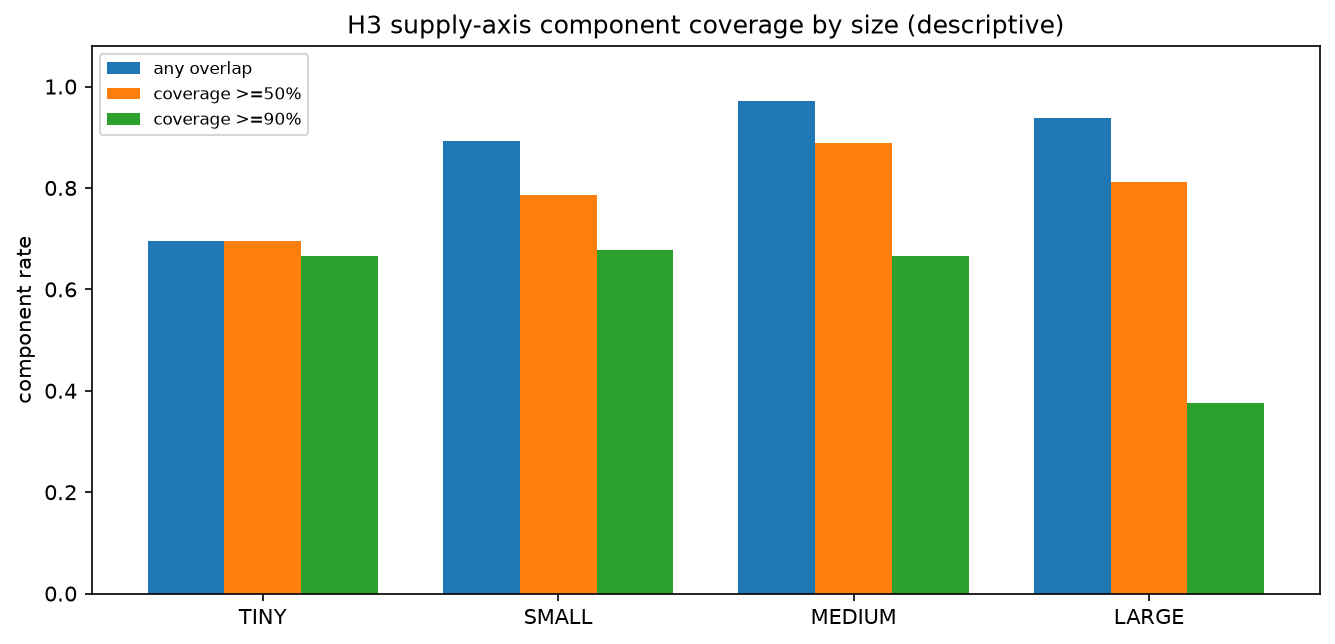

All values above are DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE


In [31]:
# ── Phasewise evaluation / visualization synchronization (post-audit) ─────────
import json as _json, hashlib as _hashlib
from pathlib import Path as _Path
import numpy as _np
import pandas as _pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as _plt
try:
    from IPython.display import display as _disp, Image as _Img
except Exception:
    _disp = print; _Img = None
_ROOT = _Path('D:/Softfors/jup')
_AUD = _ROOT / 'reports' / 'audits'
_TAB = _ROOT / 'reports' / 'tables'
_FIG = _ROOT / 'reports' / 'figures' / 'phasewise_sync'
_FIG.mkdir(parents=True, exist_ok=True)
def _sha(p): return _hashlib.sha256(_Path(p).read_bytes()).hexdigest()
def _load(p): return _json.loads(_Path(p).read_text(encoding='utf-8'))
def _show(p, w=840):
    if _Img is not None and _Path(p).exists():
        _disp(_Img(filename=str(p), width=w))
LBL      = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE'
LBL_H3   = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE'
LBL_STAT = 'DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT'

psum = _pd.read_csv(_TAB / 'project_evaluation_proposal_metrics_summary.csv')
_disp(psum[psum['arm'].str.contains('H3')])

curves = _load(_TAB / 'project_evaluation_proposal_curves.json')
d = curves.get('H3_PROPOSAL_SUPPLY', {})
print('H3 proposal PR curve meaningful :', d.get('pr_curve_meaningful'))
print('Reason                          :', d.get('pr_curve_not_meaningful_reason'))
print('Operating threshold (annotated) :', d.get('operating_point_threshold'))

h3c = _pd.read_csv(_TAB / 'h3_supply_eval_per_component.csv')
rows = []
for s in ['TINY', 'SMALL', 'MEDIUM', 'LARGE']:
    sub = h3c[h3c['size_stratum'] == s]
    rows.append({'size_stratum': s, 'n': int(len(sub)),
                 'any_overlap_rate': float(sub['any_overlap'].mean()),
                 'coverage50_rate': float(sub['coverage50_success'].mean()),
                 'coverage90_rate': float(sub['coverage90_success'].mean()),
                 'metric_domain': 'LOCALIZATION_PROPOSAL_SUPPLY', 'label': LBL_H3})
_disp(_pd.DataFrame(rows).round(6))

fig, ax = _plt.subplots(figsize=(9, 4.4))
order = ['TINY', 'SMALL', 'MEDIUM', 'LARGE']
x = _np.arange(len(order)); w = 0.26
for i, (col, nm) in enumerate([('any_overlap_rate', 'any overlap'),
                               ('coverage50_rate', 'coverage >=50%'),
                               ('coverage90_rate', 'coverage >=90%')]):
    vals = [float([r for r in rows if r['size_stratum'] == s][0][col]) for s in order]
    ax.bar(x + i * w - w, vals, w, label=nm)
ax.set_xticks(x); ax.set_xticklabels(order); ax.set_ylim(0, 1.08)
ax.set_ylabel('component rate'); ax.set_title('H3 supply-axis component coverage by size (descriptive)')
ax.legend(fontsize=8)
_plt.tight_layout(); _p = _FIG / 'h3_05_supply_coverage_by_size.png'
_plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)

print('All values above are', LBL_H3)